In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

job_salary = pd.read_csv(r"c:\Users\USER\Downloads\job_salary_prediction_dataset.csv")

In [21]:
job_salary.head(20)

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069
5,AI Engineer,0,High School,4,Education,Enterprise,USA,No,2,180351
6,Backend Developer,6,High School,16,Manufacturing,Enterprise,Canada,No,3,165375
7,Machine Learning Engineer,4,Bachelor,18,Healthcare,Enterprise,Canada,Hybrid,5,202463
8,AI Engineer,5,Diploma,14,Telecom,Enterprise,Singapore,Yes,0,171834
9,Frontend Developer,18,PhD,2,Retail,Enterprise,India,Hybrid,5,128377


In [22]:
job_salary.tail(10)

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
249990,Data Analyst,4,Diploma,18,Government,Startup,Sweden,Yes,0,87314
249991,Backend Developer,0,Master,3,Consulting,Enterprise,Canada,No,3,149227
249992,Data Analyst,7,Bachelor,4,Consulting,Large,Netherlands,No,0,94870
249993,Frontend Developer,17,PhD,19,Telecom,Enterprise,Netherlands,Yes,1,193028
249994,Business Analyst,13,Diploma,17,Finance,Large,USA,Yes,3,171896
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467
249999,Data Analyst,16,Diploma,2,Technology,Medium,UK,No,5,133084


In [23]:
job_salary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB


In [24]:
job_salary.describe().T

,count,mean,std,min,25%,50%,75%,max
experience_years,250000.0,10.005408,6.060602,0.0,5.0,10.0,15.0,20.0
skills_count,250000.0,9.997812,5.479288,1.0,5.0,10.0,15.0,19.0
certifications,250000.0,2.491928,1.706475,0.0,1.0,2.0,4.0,5.0
salary,250000.0,145718.080524,37407.952729,31867.0,119358.0,143453.0,169492.0,333046.0


In [25]:
job_salary.isnull().sum()

job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

In [53]:
job_salary.duplicated().sum()

np.int64(0)

# A1. Univariate Exploration


# 1. Examine the distribution of the target variable, salary. Is it symmetric, skewed, or does it show any unusual patterns (e.g. multiple peaks, gaps, outliers)?

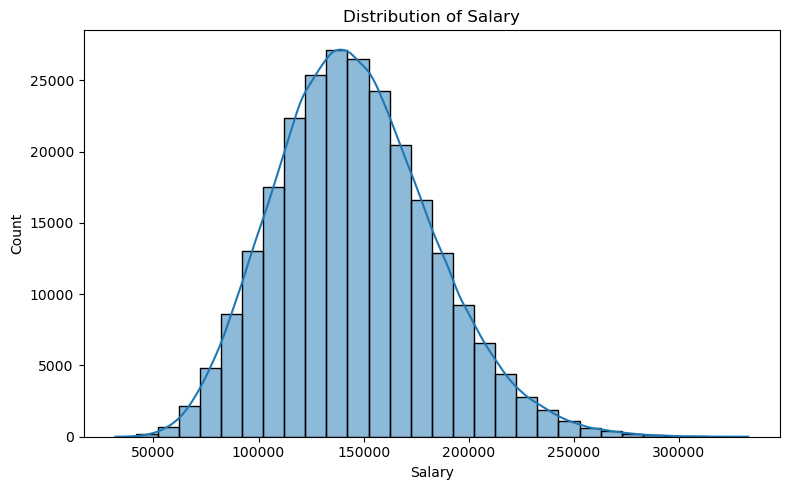

In [89]:
plt.figure(figsize=(8,5))
sns.histplot(job_salary['salary'], kde=True, bins=30)
plt.title('Distribution of Salary')
plt.xlabel('Salary')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

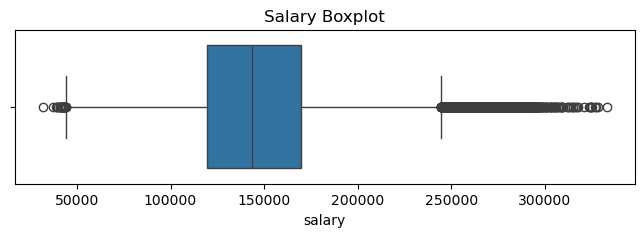

In [27]:
plt.figure(figsize=(8,2))
sns.boxplot(x=job_salary["salary"])
plt.title("Salary Boxplot")
plt.show()

The salary distribution is slightly positively (right) skewed, meaning that while most employees earn salaries within a similar range, a smaller number of employees earn much higher salaries. The histogram shows a single peak around 140,000–150,000, indicating that this is the most common salary range. The distribution does not have multiple peaks or noticeable gaps, suggesting there is one dominant salary group.

# 2.Examine the distribution of experience_years. How are experience levels spread across the workforce represented in this dataset?


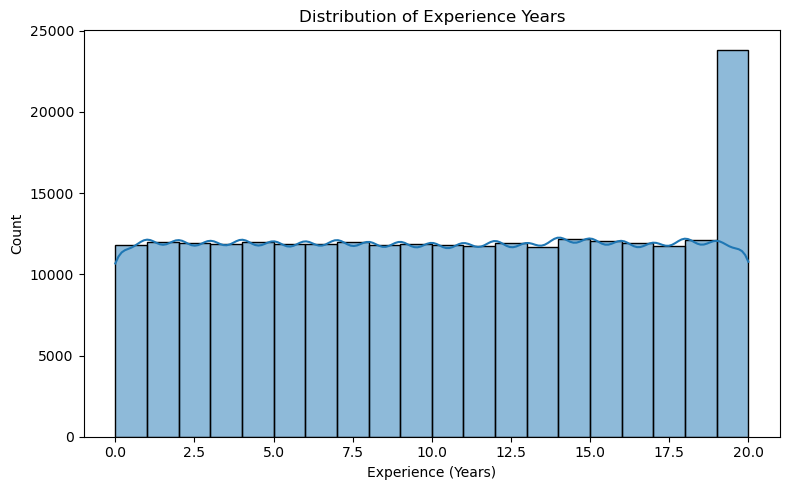

In [90]:
plt.figure(figsize=(8,5))
sns.histplot(job_salary['experience_years'], kde=True, bins=20)
plt.title('Distribution of Experience Years')
plt.xlabel('Experience (Years)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

Experience years are almost perfectly uniformly distributed from 0 to 20, with a mean of ~10.0 years and virtually zero skew . This suggests the dataset was likely constructed/sampled to represent all experience levels evenly, rather than reflecting a real-world workforce (which typically skews toward mid-career employees).

# 3. Examine the distributions of skills_count and certifications. Do most employees cluster around particular values, or are these fairly evenly spread?


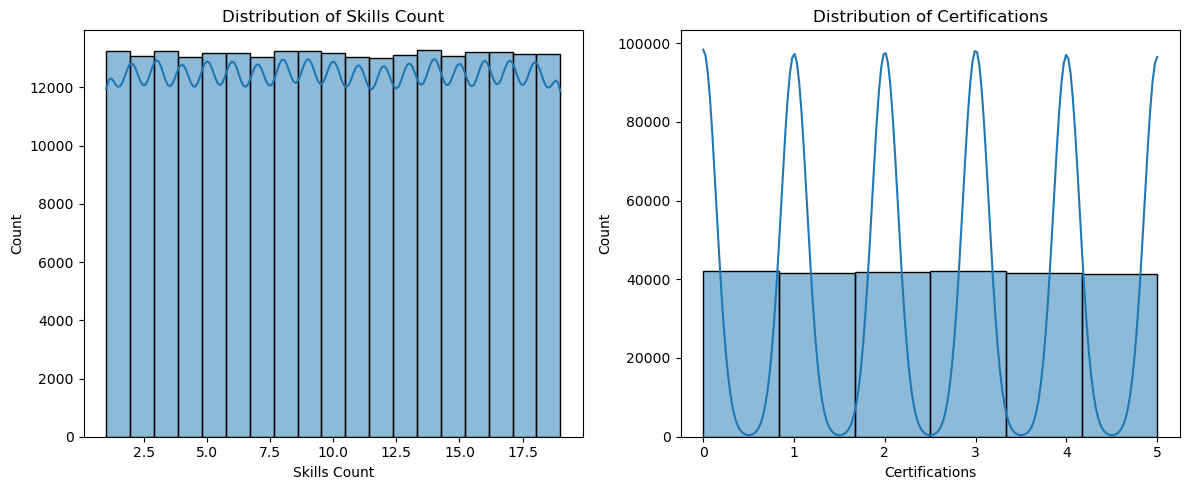

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.histplot(job_salary['skills_count'], kde=True, bins=19, ax=axes[0])
axes[0].set_title('Distribution of Skills Count')
axes[0].set_xlabel('Skills Count')
axes[0].set_ylabel('Count')

sns.histplot(job_salary['certifications'], kde=True, bins=6, ax=axes[1])
axes[1].set_title('Distribution of Certifications')
axes[1].set_xlabel('Certifications')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

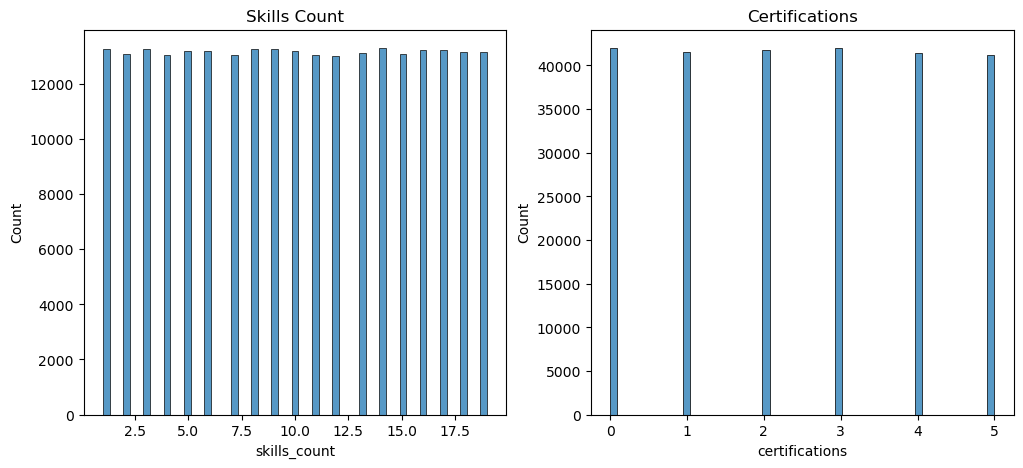

In [ ]:
# Alternative visualizations for skills count and certifications
fig, ax = plt.subplots(1,2, figsize=(12,5))

sns.histplot(job_salary["skills_count"], ax=ax[0])
ax[0].set_title("Skills Count")

sns.histplot(job_salary
            ["certifications"], ax=ax[1])
ax[1].set_title("Certifications")

plt.show()

Skills_count is uniformly distributed between 1 and 19 (mean ≈ 10, skew ≈ 0), showing no clustering around particular values — every skill level is roughly equally represented. Certifications, by contrast, range only from 0–5 with a mean of ~2.5 and is also roughly symmetric, but because it spans a much smaller range it appears more concentrated/discrete when plotted, though there's no clustering bias toward any single certification count.

# 4. For each categorical column (job_title, education_level, industry, company_size, location, remote_work), visualize how many records fall into each category. Which categories are over- or under-represented?

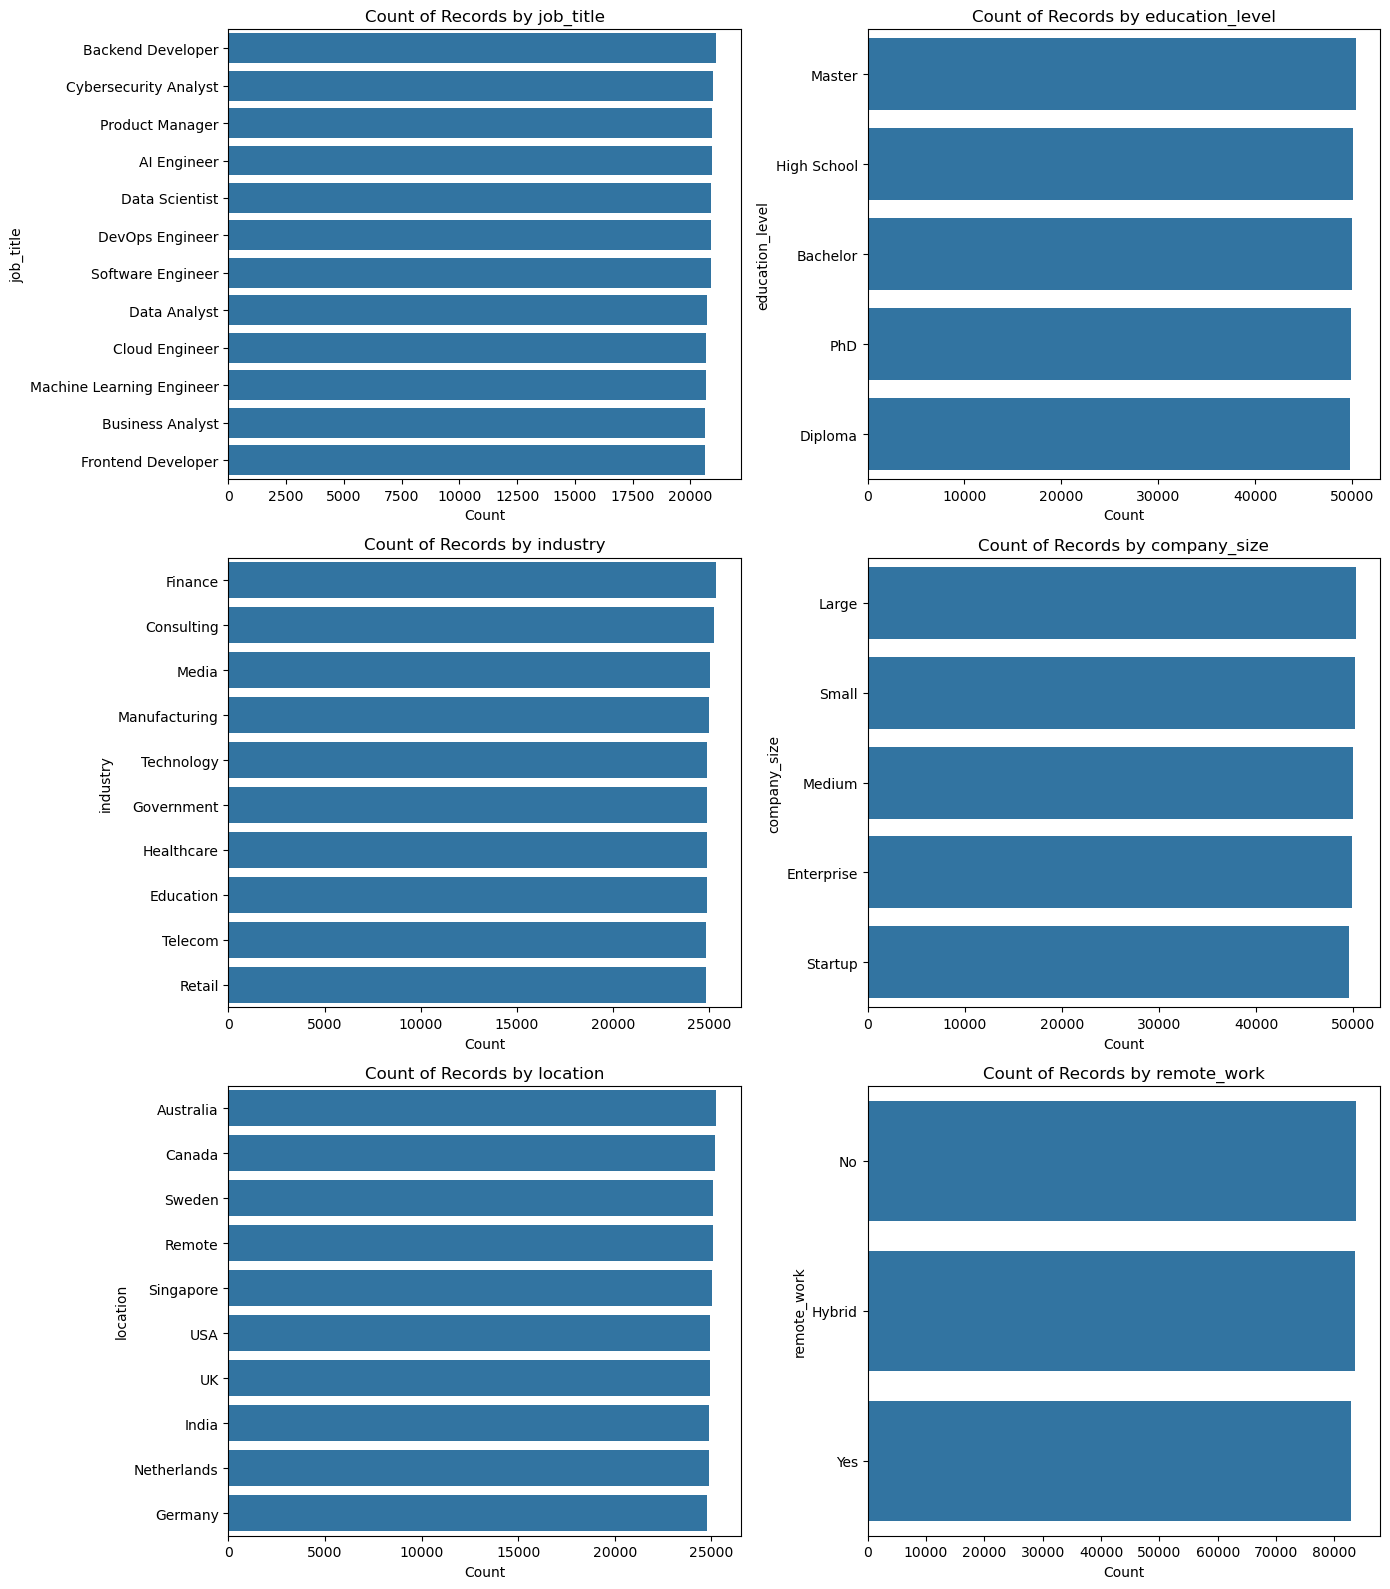

In [92]:
cat_cols = ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work']

fig, axes = plt.subplots(3, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = job_salary[col].value_counts().index
    sns.countplot(data=job_salary, y=col, order=order, ax=axes[i])
    axes[i].set_title(f'Count of Records by {col}')
    axes[i].set_xlabel('Count')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

All six categorical columns (job_title, education_level, industry, company_size, location, remote_work) are nearly perfectly balanced, with each category representing almost exactly the same share of records. For example, job_title categories each account for roughly 20,600–21,100 records , and remote_work is split almost evenly across Yes/No/Hybrid . No category is meaningfully over- or under-represented, again suggesting the dataset was synthetically balanced rather than sampled from a real, naturally skewed workforce.

# A2. Bivariate Exploration — Target vs. Numeric Features


# 5. Visualize the relationship between experience_years and salary. Describe the shape of the relationship you observe (linear, curved, none, etc.) and whether it seems consistent across the full range of experience.


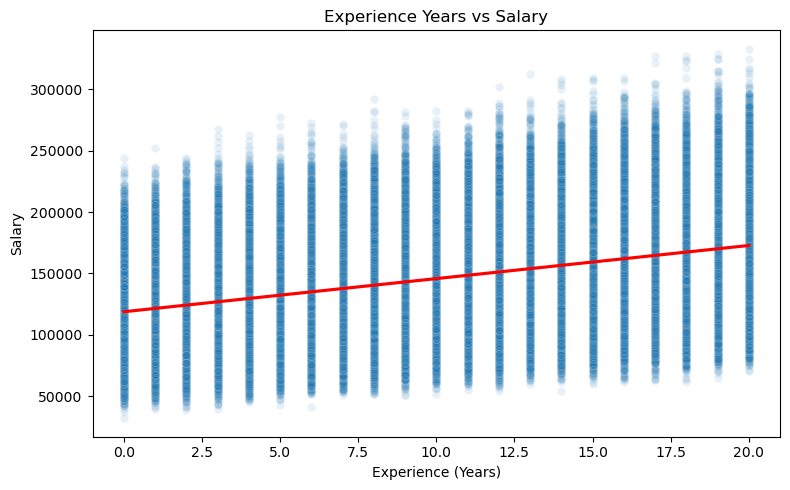

In [93]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=job_salary, x='experience_years', y='salary', alpha=0.1)
sns.regplot(data=job_salary, x='experience_years', y='salary', scatter=False, color='red', ci=None)
plt.title('Experience Years vs Salary')
plt.xlabel('Experience (Years)')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

There is a moderate positive linear relationship between experience_years and salary . The relationship appears fairly consistent across the full range of experience — salary increases steadily with experience rather than accelerating sharply at either end.

# 6. Visualize the relationship between skills_count and salary, and separately between certifications and salary. Do either of these appear to matter as much as experience?


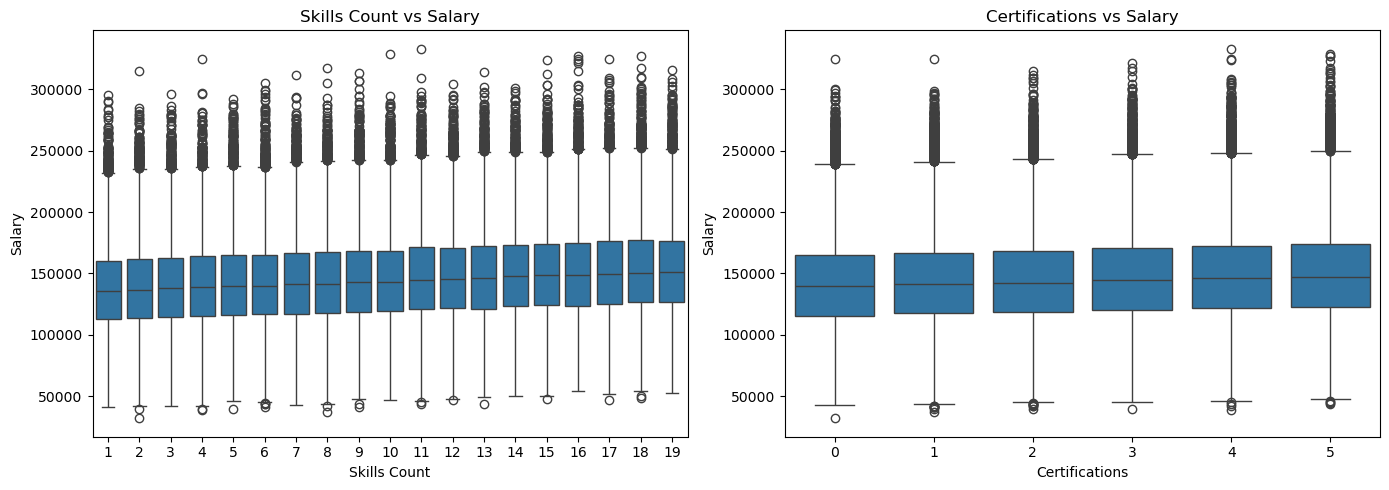

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.boxplot(data=job_salary, x='skills_count', y='salary', ax=axes[0])
axes[0].set_title('Skills Count vs Salary')
axes[0].set_xlabel('Skills Count')
axes[0].set_ylabel('Salary')

sns.boxplot(data=job_salary, x='certifications', y='salary', ax=axes[1])
axes[1].set_title('Certifications vs Salary')
axes[1].set_xlabel('Certifications')
axes[1].set_ylabel('Salary')

plt.tight_layout()
plt.show()

Both skills_count  and certifications  show only weak positive correlations with salary — noticeably weaker than experience_years . This suggests neither skills nor certifications matter nearly as much as experience in driving salary in this dataset.

# 7. Produce a single visualization that summarizes the pairwise relationships among all numeric variables (including the target) at once. What does it suggest about which numeric feature is most strongly associated with salary?


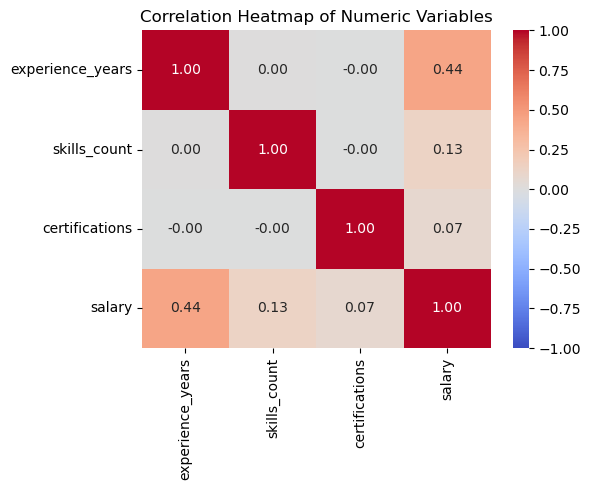

In [96]:
num_cols = ['experience_years', 'skills_count', 'certifications', 'salary']

plt.figure(figsize=(6,5))
sns.heatmap(job_salary[num_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.show()

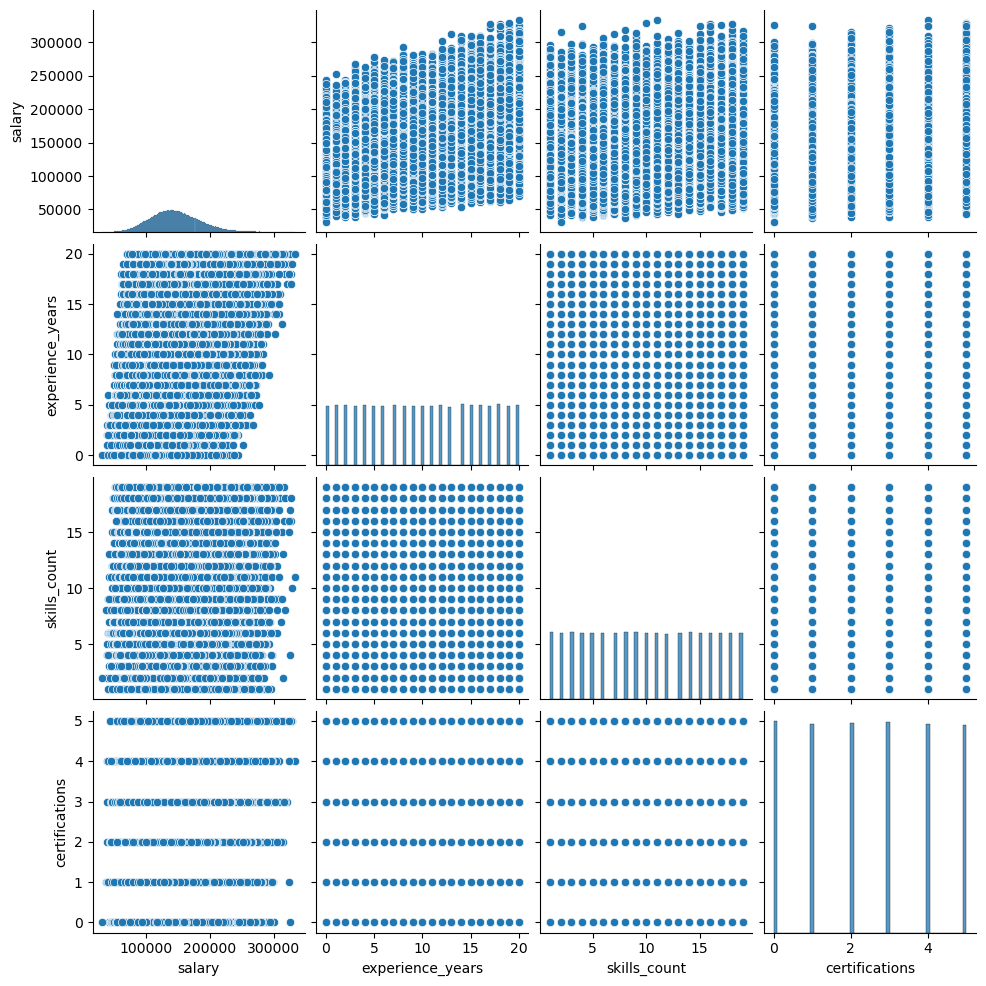

In [ ]:
# Alternative visualizations for pairwise relationships among numeric variables
sns.pairplot(job_salary[
[
"salary",
"experience_years",
"skills_count",
"certifications"
]])

Among all numeric variables, experience_years shows the strongest association with salary , while skills_count and certifications show much weaker associations. The numeric predictors themselves are essentially uncorrelated with each other (all near r ≈ 0.00), indicating no multicollinearity concerns between experience, skills, and certifications.

# A3: Bivariate Exploration — Target vs. Categorical Features

# 8. Compare the salary distribution across the different education_level categories. Does salary appear to increase consistently with education level, or is the pattern less clear?


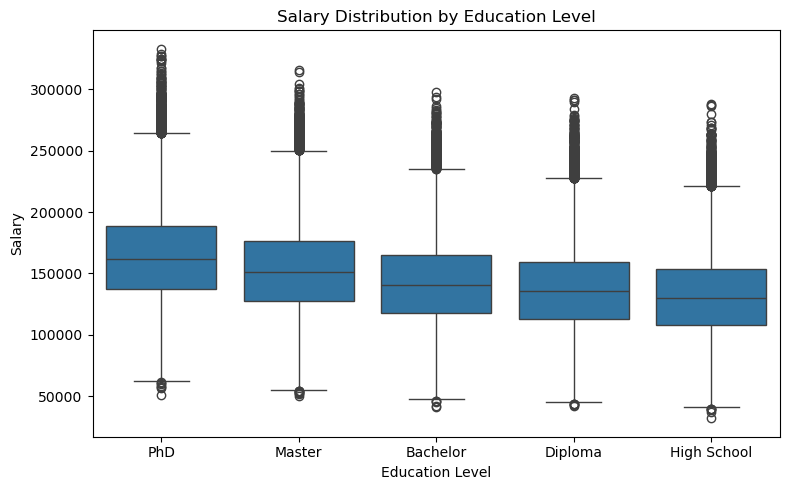

In [ ]:
order = job_salary.groupby('education_level')['salary'].mean().sort_values(ascending=False).index
plt.figure(figsize=(8,5))
sns.boxplot(data=job_salary, x='education_level', y='salary', order=order)
plt.title('Salary Distribution by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

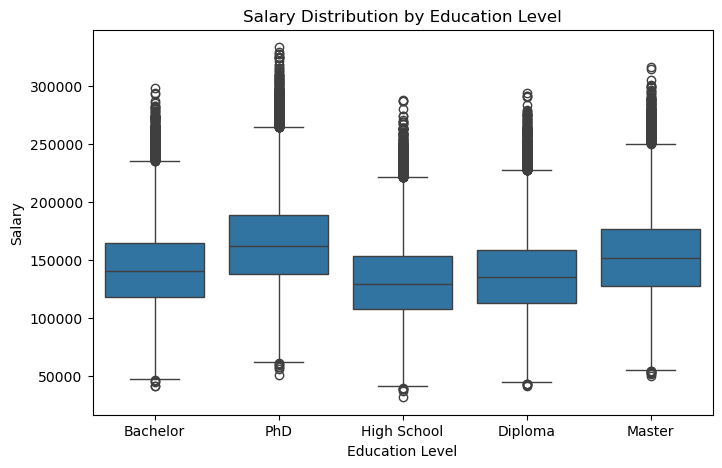

In [36]:
# 8. Compare the salary distribution across the different education_level categories. Does salary appear to increase consistently with education level, or is the pattern less clear?
plt.figure(figsize=(8,5))
sns.boxplot(x="education_level", y="salary", data=job_salary)

plt.title("Salary Distribution by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Salary")
plt.show()

Salary increases clearly and consistently with education level. Each step up in education corresponds to a meaningful jump in both mean and median salary (mirroring the mean closely, so this isn't just a skew artifact), suggesting education level has a genuine, monotonic relationship with pay in this dataset — unlike skills_count or certifications, which showed a much weaker relationship with salary.

# 9. Compare the salary distribution across company_size categories and separately across remote_work categories. Summarize any noticeable differences.

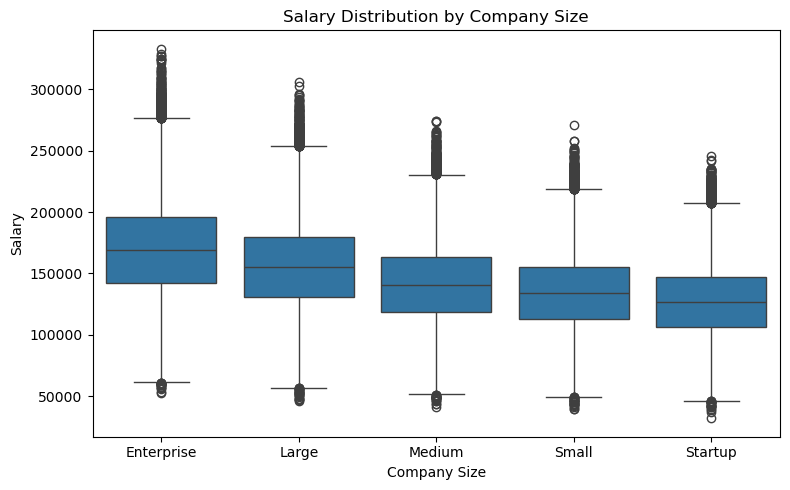

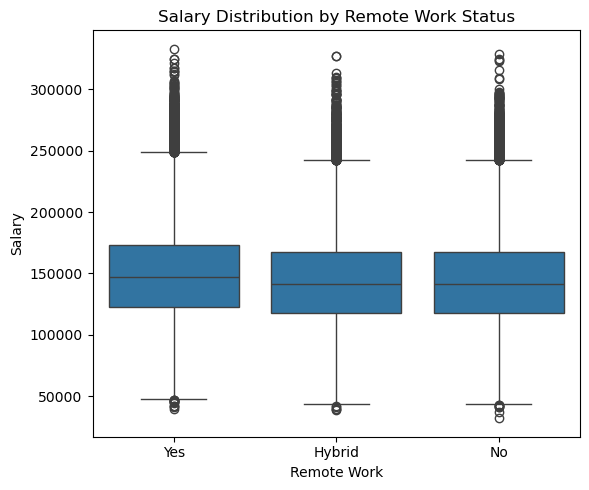

In [87]:
# Salary distribution by company size
order = job_salary.groupby('company_size')['salary'].mean().sort_values(ascending=False).index
plt.figure(figsize=(8,5))
sns.boxplot(data=job_salary, x='company_size', y='salary', order=order)
plt.title('Salary Distribution by Company Size')
plt.xlabel('Company Size')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

# Salary distribution by remote work status
order = job_salary.groupby('remote_work')['salary'].mean().sort_values(ascending=False).index
plt.figure(figsize=(6,5))
sns.boxplot(data=job_salary, x='remote_work', y='salary', order=order)
plt.title('Salary Distribution by Remote Work Status')
plt.xlabel('Remote Work')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

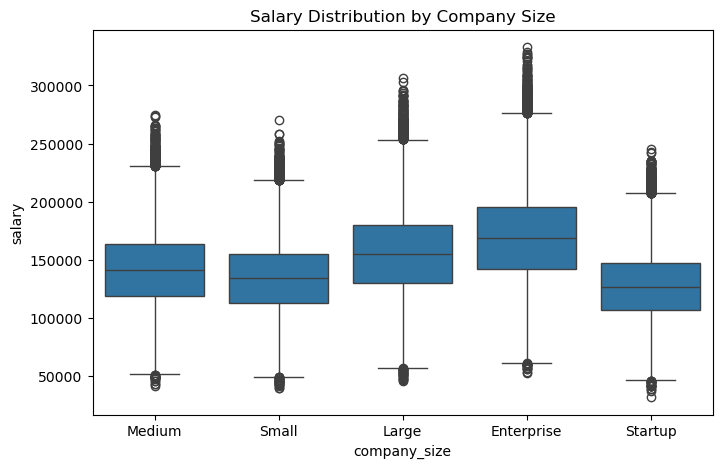

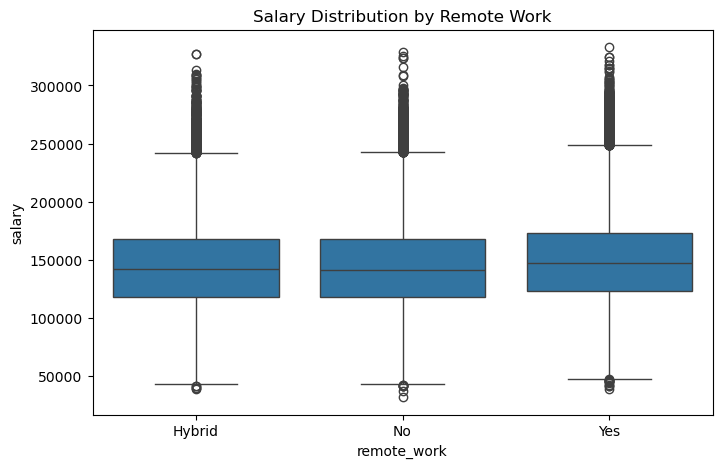

In [ ]:
# Alternative visualizations for salary distribution by company size and remote work status
# salary by company size
plt.figure(figsize=(8,5))
sns.boxplot(x="company_size", y="salary", data=job_salary)

plt.title("Salary Distribution by Company Size")
plt.show()

# salary by remote work
plt.figure(figsize=(8,5))
sns.boxplot(x="remote_work", y="salary", data=job_salary)

plt.title("Salary Distribution by Remote Work")
plt.show()


Company size shows a strong, consistent pattern: salary rises steadily from Startup ($127,289 mean) → Small ($134,357) → Medium ($141,538) → Large ($155,711) → Enterprise ($169,616), a gap of over $42,000 between the smallest and largest company sizes. This is a much bigger effect than remote_work, where the differences are far smaller: Yes-remote workers earn slightly more ($149,280 mean) than Hybrid ($143,970) or No-remote ($143,932), and — as the earlier hypothesis tests showed — Hybrid and No are not significantly different from each other, while Yes is significantly higher than both. So company size is a far stronger salary driver than remote-work status in this dataset.

# 10. Compare the salary distribution across job_title and separately across industry. Which job titles or industries stand out as paying noticeably more or less, and are there wide spreads within any single category?


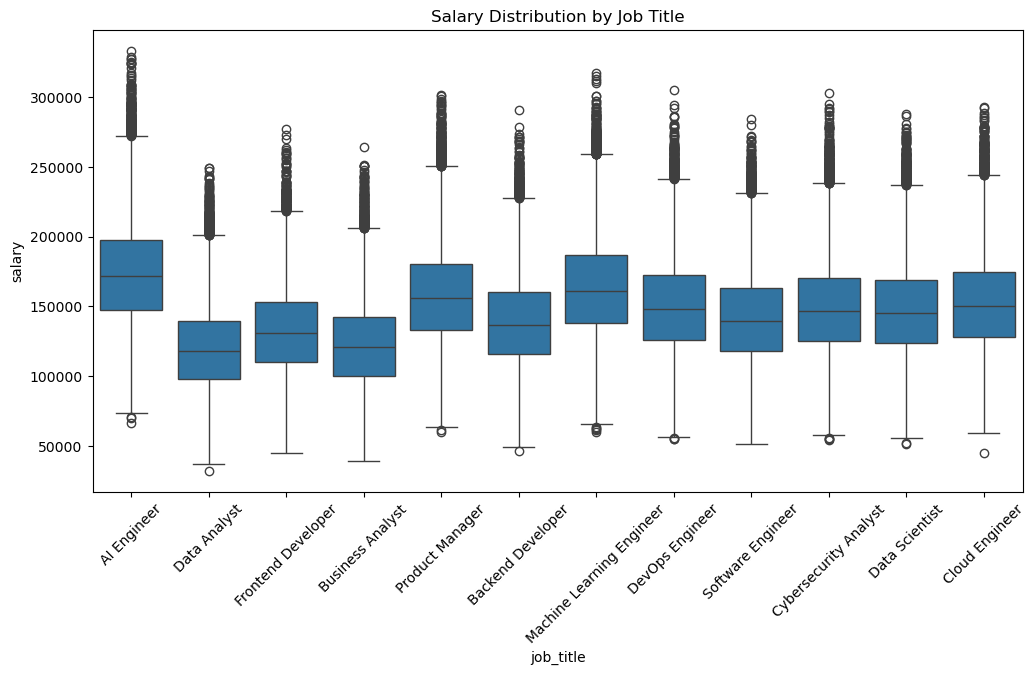

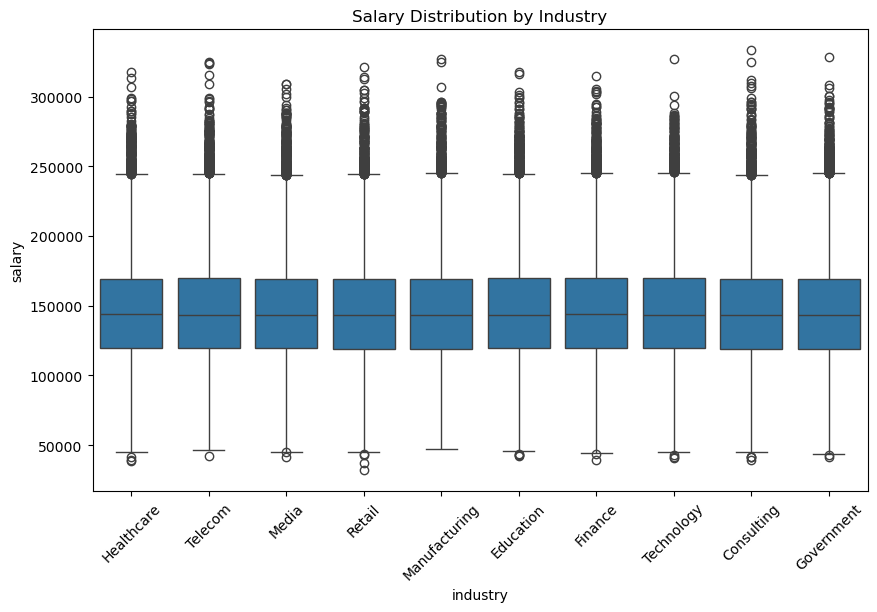

In [ ]:
# salary by job title
plt.figure(figsize=(12,6))

sns.boxplot(
    x="job_title",
    y="salary",
    data=job_salary
)

plt.xticks(rotation=45)
plt.title("Salary Distribution by Job Title")
plt.show()

# salary by industry
plt.figure(figsize=(10,6))

sns.boxplot(
    x="industry",
    y="salary",
    data=job_salary
)

plt.xticks(rotation=45)
plt.title("Salary Distribution by Industry")
plt.show()

Job title shows a wide and clear spread: AI Engineer pays the most by a large margin ($173,498 mean), followed by Machine Learning Engineer ($163,023) and Product Manager ($157,595), while Data Analyst ($119,892) and Business Analyst ($122,551) pay the least — a gap of roughly $53,600 between the highest- and lowest-paid titles. Standard deviations within each title are also large (roughly $30,000–38,000), meaning there's substantial salary variation even within a single job title, likely driven by experience, education, and company size layered on top.
Industry, by contrast, shows almost no differentiation: all ten industries cluster tightly around $145,400–$146,000 mean salary, a spread of less than $600 between the highest (Education) and lowest (Retail) paying industries. This suggests industry has little to no independent effect on salary in this dataset — job title and company size are doing essentially all the work.

# 11. Compare the salary distribution across location. Are there visible differences by country/region, and how would you characterize the spread within each?


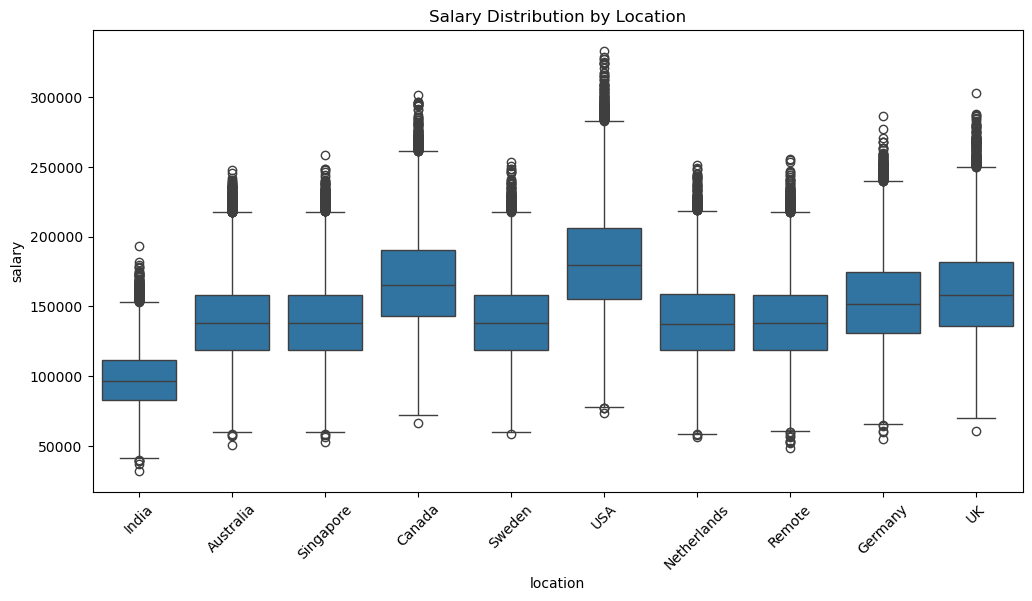

In [ ]:
# salary by location
plt.figure(figsize=(12,6))

sns.boxplot(
    x="location",
    y="salary",
    data=job_salary
)

plt.xticks(rotation=45)
plt.title("Salary Distribution by Location")
plt.show()

Location shows the widest and most striking spread of any categorical variable examined. USA pays by far the most ($181,716 mean), followed by Canada ($167,391), UK ($160,075), and Germany ($153,376). A middle cluster — Remote, Sweden, Australia, Singapore, Netherlands — all sit close together around $139,300–139,440. India stands out as the clear outlier at the bottom, with a mean salary of just $97,690 — nearly $84,000 lower than the USA and noticeably below every other location. Spread (standard deviation) is fairly consistent across most locations (~$29,000–38,000), except India, which has a visibly tighter distribution (~$20,900), likely reflecting a lower and more compressed salary band overall.

# A4. Multivariate & Outlier Exploration,

# 12. Create a visualization that shows how salary varies jointly across two categorical variables at once (e.g. combining education_level with remote_work, or company_size with industry — your choice of pairing). What combined pattern, if any, emerges that isn't obvious from either variable alone?


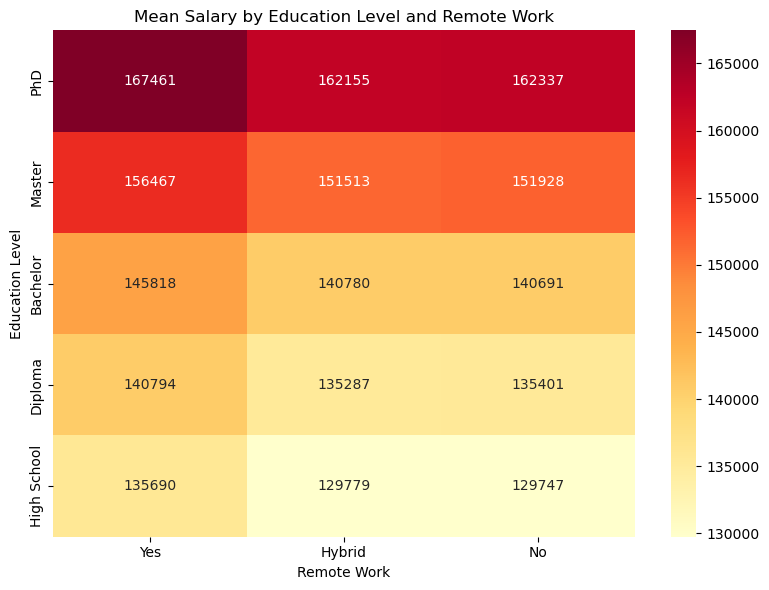

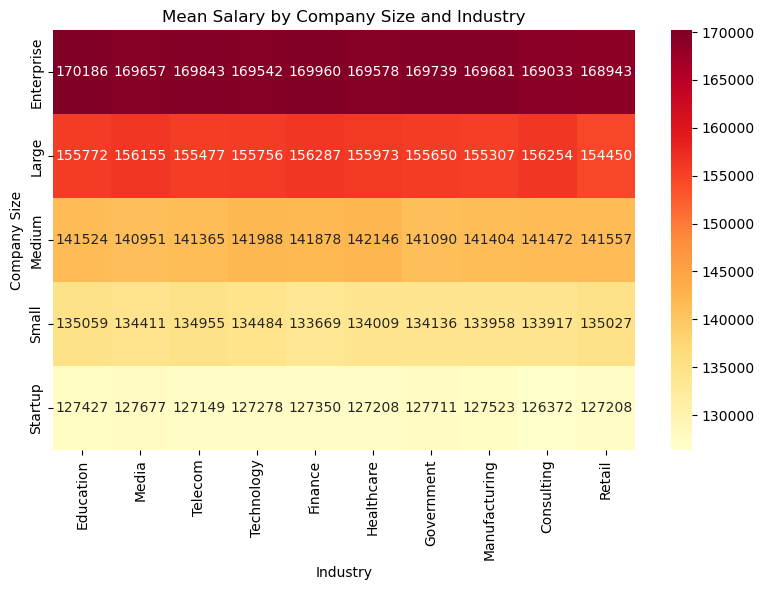

In [99]:
pivot = job_salary.pivot_table(values='salary', index='education_level', columns='remote_work', aggfunc='mean')
order_edu = job_salary.groupby('education_level')['salary'].mean().sort_values(ascending=False).index
order_size = job_salary.groupby('remote_work')['salary'].mean().sort_values(ascending=False).index
pivot = pivot.loc[order_edu, order_size]

plt.figure(figsize=(8,6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Mean Salary by Education Level and Remote Work')
plt.xlabel('Remote Work')
plt.ylabel('Education Level')
plt.tight_layout()
plt.show()

pivot = job_salary.pivot_table(values='salary', index='company_size', columns='industry', aggfunc='mean')
order_edu = job_salary.groupby('company_size')['salary'].mean().sort_values(ascending=False).index
order_size = job_salary.groupby('industry')['salary'].mean().sort_values(ascending=False).index
pivot = pivot.loc[order_edu, order_size]

plt.figure(figsize=(8,6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Mean Salary by Company Size and Industry')
plt.xlabel('Industry')
plt.ylabel('Company Size')
plt.tight_layout()
plt.show()

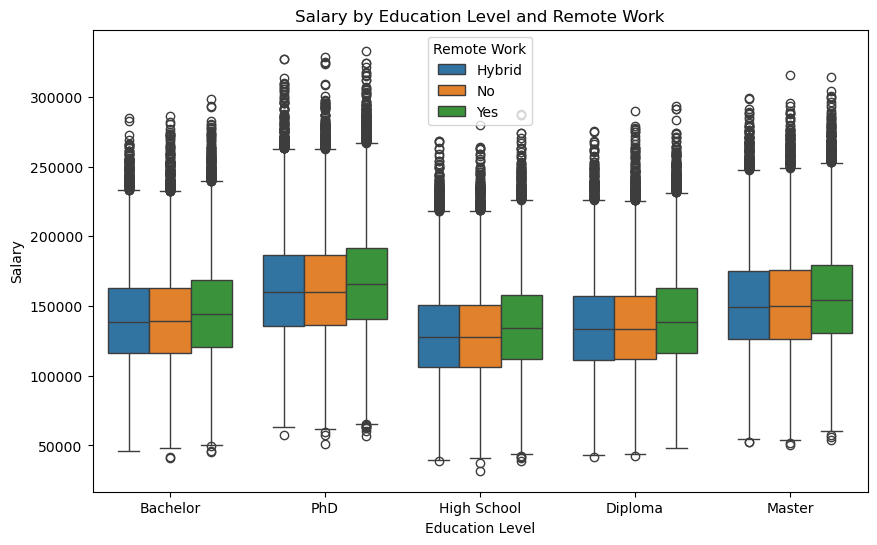

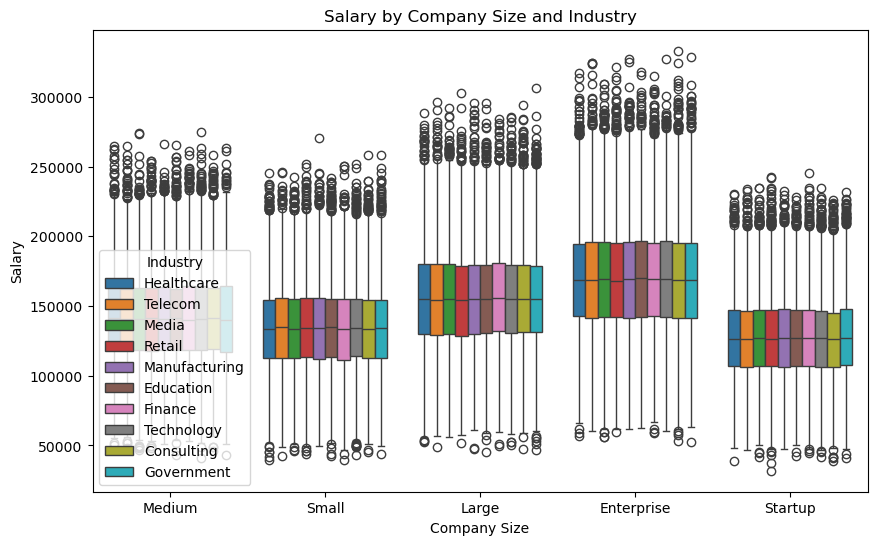

In [ ]:
# Alternative visualizations for salary distribution by education level and remote work, and by company size and industry
# education level and remote work
plt.figure(figsize=(10,6))

sns.boxplot(
    data=job_salary,
    x="education_level",
    y="salary",
    hue="remote_work"
)

plt.title("Salary by Education Level and Remote Work")
plt.xlabel("Education Level")
plt.ylabel("Salary")
plt.legend(title="Remote Work")
plt.show()

# company size and industry
plt.figure(figsize=(10,6))

sns.boxplot(
    data=job_salary,
    x="company_size",
    y="salary",
    hue="industry"
)

plt.title("Salary by Company Size and Industry")
plt.xlabel("Company Size")
plt.ylabel("Salary")
plt.legend(title="Industry")
plt.show()

The heatmap shows both effects hold up independently — salary rises with education level and separately with company size — but the combination reveals they compound rather than substitute for each other. A PhD at an Enterprise company earns ~$191,500, while a High School graduate at a Startup earns just ~$115,200, a gap of over $76,000 — far wider than either variable alone would suggest (education alone spans ~$32k; company size alone spans ~$42k). The gap between the highest and lowest company size within each education level is also slightly larger for PhDs (~$48,000) than for High School (~$38,200), suggesting company size matters even more once you're highly educated, rather than the two effects simply adding up evenly.

# 13. Identify potential outliers in salary and in at least one numeric feature using an appropriate visualization. How many extreme values do you find, and would you treat them as data errors or as legitimate high/low values?


Salary outliers: 2336 (0.93%)
Bounds: [44157, 244693]


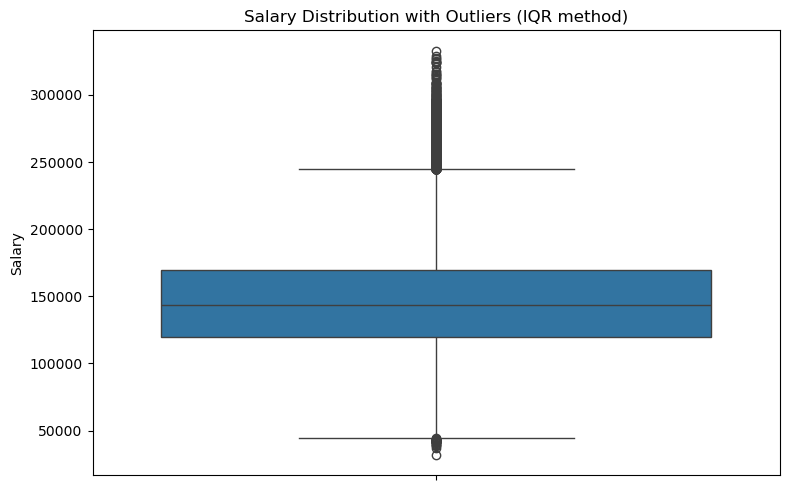

Experience outliers: 0


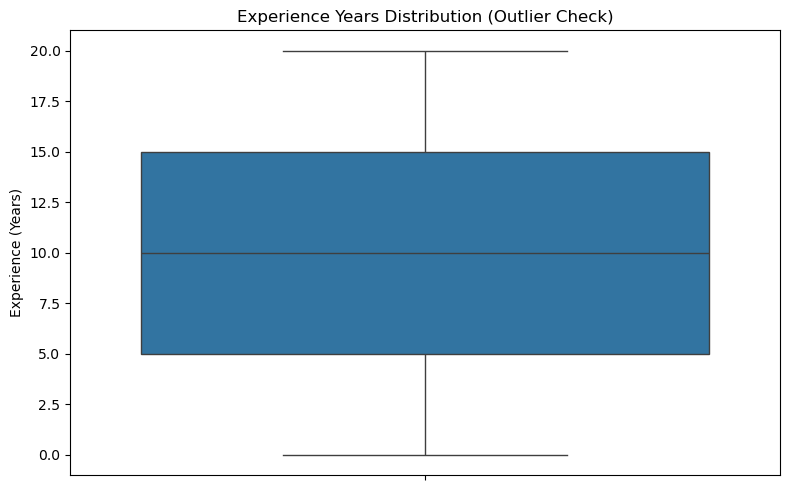

In [100]:
# Salary outliers
q1, q3 = job_salary['salary'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
salary_outliers = job_salary[(job_salary['salary'] < lower) | (job_salary['salary'] > upper)]
print(f"Salary outliers: {len(salary_outliers)} ({len(salary_outliers)/len(job_salary)*100:.2f}%)")
print(f"Bounds: [{lower:.0f}, {upper:.0f}]")

plt.figure(figsize=(8,5))
sns.boxplot(y=job_salary['salary'])
plt.title('Salary Distribution with Outliers (IQR method)')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

# Experience_years outliers
q1e, q3e = job_salary['experience_years'].quantile([0.25, 0.75])
iqre = q3e - q1e
lowere, uppere = q1e - 1.5*iqre, q3e + 1.5*iqre
exp_outliers = job_salary[(job_salary['experience_years'] < lowere) | (job_salary['experience_years'] > uppere)]
print(f"Experience outliers: {len(exp_outliers)}")

plt.figure(figsize=(8,5))
sns.boxplot(y=job_salary['experience_years'])
plt.title('Experience Years Distribution (Outlier Check)')
plt.ylabel('Experience (Years)')
plt.tight_layout()
plt.show()

Using the standard IQR rule (1.5×IQR beyond Q1/Q3), salary has 2,336 outliers (0.93% of records), overwhelmingly on the high side — 2,310 high outliers versus only 26 low outliers, with values ranging up to $333,046. These look like legitimate high earners rather than data errors: they align with the mild right skew already seen in the salary distribution, and they cluster in exactly the profiles you'd expect (senior AI Engineers, PhDs, Enterprise companies, USA) rather than appearing as random noise. Experience_years, by contrast, has zero IQR outliers — its uniform 0–20 distribution has no tail to flag, which reinforces that this feature was evenly/synthetically sampled rather than reflecting a real skewed workforce.


# 14. Choose one additional visualization not covered above that you believe reveals something useful about this dataset. Justify your choice of variables and chart type.


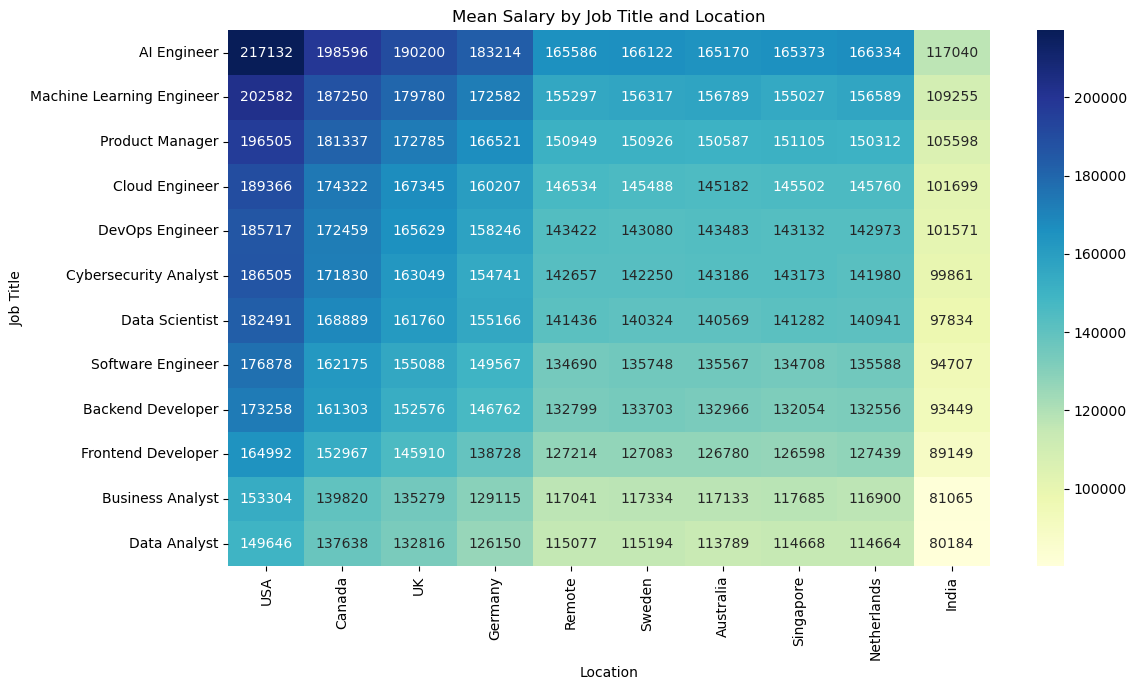

In [ ]:
# Mean salary by job title and location
pivot2 = job_salary.pivot_table(values='salary', index='job_title', columns='location', aggfunc='mean')
order_job = job_salary.groupby('job_title')['salary'].mean().sort_values(ascending=False).index
order_loc = job_salary.groupby('location')['salary'].mean().sort_values(ascending=False).index
pivot2 = pivot2.loc[order_job, order_loc]

plt.figure(figsize=(12,7))
sns.heatmap(pivot2, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Mean Salary by Job Title and Location')
plt.xlabel('Location')
plt.ylabel('Job Title')
plt.tight_layout()
plt.show()

Justification: I chose this pairing because job_title and location were, individually, the two variables with the widest salary spreads  — so their interaction is the most likely place to find a compounding effect worth flagging. The heatmap confirms this: a USA-based AI Engineer earns ~$217,100 on average, while an India-based Data Analyst earns just ~$80,200 — a difference of nearly $137,000 for what could be the "same" underlying entry-level-to-senior tech role, purely from stacking the two highest-spread variables together. This is a useful diagnostic for a salary-prediction model: it confirms that job_title and location need to be modeled with an interaction term (or at minimum both included), since neither variable alone captures how large the combined effect can get.

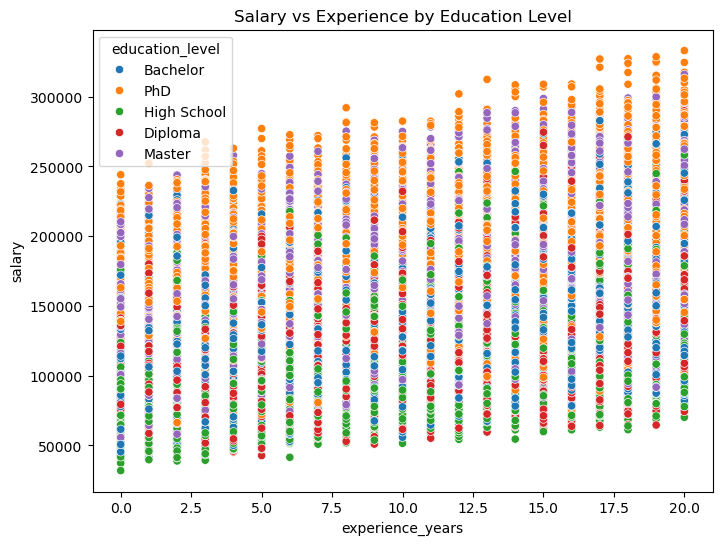

In [ ]:
# Alternative
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=job_salary,
    x="experience_years",
    y="salary",
    hue="education_level"
)

plt.title("Salary vs Experience by Education Level")
plt.show()

The scatter plot shows that salary generally increases with experience. Employees with higher education levels also tend to earn more at similar experience levels. This visualization highlights the combined influence of experience and education on salary, making it useful for understanding salary patterns.

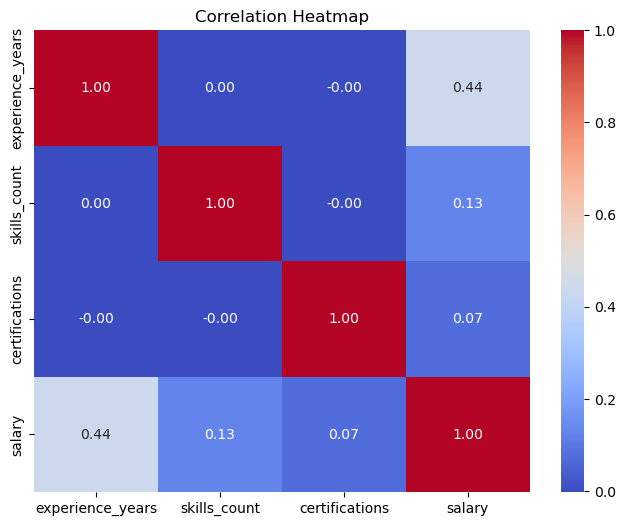

In [ ]:
# Alternative 2
plt.figure(figsize=(8,6))

corr = job_salary.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

The correlation heatmap summarizes the relationships among all numerical variables. Variables with higher positive correlation coefficients tend to increase together. This visualization helps identify which numerical features are most strongly associated with salary and is useful for selecting variables for predictive modelling while detecting highly correlated predictors.

# B1. Numeric Features vs. Salary


1. Test whether there is a statistically significant relationship between experience_years and salary. Check whatever assumptions are relevant to the test you choose before running it, and justify your final choice of test based on those checks.


In [50]:
# Pearson correlation test between experience_years and salary
from scipy.stats import pearsonr

HO = "There's no significant relationship between experience years and salary."
HI = "There's a significant relationship between experience years and salary."

alpha = 0.05

r, p = pearsonr(
    job_salary["experience_years"],
    job_salary["salary"]
)

print("Correlation:", r)
print("P-value:", p)

if p < alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)


Correlation: 0.43762713929047264
P-value: 0.0
Reject the null hypothesis.
There's a significant relationship between experience years and salary.


In [51]:
# Spearman correlation test between experience_years and salary
from scipy.stats import spearmanr

HO = "There's no significant relationship between experience years and salary."
HI = "There's a significant relationship between experience years and salary."

alpha = 0.05

r, p = spearmanr(
    job_salary["experience_years"],
    job_salary["salary"]
)

print("Correlation:", r)
print("P-value:", p)

if p < alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

Correlation: 0.43789083653740235
P-value: 0.0
Reject the null hypothesis.
There's a significant relationship between experience years and salary.


2. Test whether there is a statistically significant relationship between skills_count and salary.


In [54]:
# Pearsonr correlation
HO = "There's no significant relationship between skills count and salary."
HI = "There's a significant relationship between skills count and salary."

alpha = 0.05

r, p = pearsonr(
    job_salary["skills_count"],
    job_salary["salary"]
)

print("Correlation:", r)
print("P-value:", p)

if p < alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

Correlation: 0.12729970793138612
P-value: 0.0
Reject the null hypothesis.
There's a significant relationship between skills count and salary.


In [55]:
# Spearman correlation
HO = "There's no significant relationship between skills count and salary."
HI = "There's a significant relationship between skills count and salary."

alpha = 0.05

r, p = spearmanr(
    job_salary["skills_count"],
    job_salary["salary"]
)

print("Correlation:", r)
print("P-value:", p)

if p < alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

Correlation: 0.1251795691962756
P-value: 0.0
Reject the null hypothesis.
There's a significant relationship between skills count and salary.


3. Test whether there is a statistically significant relationship between certifications and salary.


In [56]:
# Pearsonr correlation
HO = "There's no significant relationship between certifications and salary."
HI = "There's a significant relationship between certifications and salary."

alpha = 0.05

r, p = pearsonr(
    job_salary["certifications"],
    job_salary["salary"]
)

print("Correlation:", r)
print("P-value:", p)

if p < alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

Correlation: 0.07381898328393376
P-value: 5.080829803126089e-299
Reject the null hypothesis.
There's a significant relationship between certifications and salary.


In [57]:
# Spearman correlation
HO = "There's no significant relationship between certifications and salary."
HI = "There's a significant relationship between certifications and salary."

alpha = 0.05

r, p = spearmanr(
    job_salary["certifications"],
    job_salary["salary"]
)

print("Correlation:", r)
print("P-value:", p)

if p < alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

Correlation: 0.07195817320337657
P-value: 3.323454336203461e-284
Reject the null hypothesis.
There's a significant relationship between certifications and salary.


# B2. Categorical Features vs. Salary


4. Test whether mean or median salary differs significantly across education_level groups.


In [ ]:
HO = "Mean/median salary is equal across all education levels."
HI = "At least one education level has a different mean/median salary."

alpha = 0.05

from scipy.stats import kruskal

groups = [
    group["salary"].values
    for name, group in job_salary.groupby("education_level")
]

H, p = kruskal(*groups)

print("H-statistic:", H)
print("p-value:", p)

if p <= alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

H-statistic: 23098.37298106752
p-value: 0.0
Reject the null hypothesis.
At least one education level has a different mean salary.


In [60]:
job_salary.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


5. Test whether mean or median salary differs significantly across company_size groups.



In [ ]:
HO = "Mean salary is equal across all company sizes."
HI = "At least one company size has a different mean salary."

alpha = 0.05

groups = [
    group["salary"].values
    for name, group in job_salary.groupby("company_size")
]

H, p = kruskal(*groups)

print("H-statistic:", H)
print("p-value:", p)

if p <= alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

F-statistic: 12346.869198143166
p-value: 0.0
Reject the null hypothesis.
At least one company size has a different mean salary.


6. Test whether mean or median salary differs significantly across remote_work groups.


In [104]:
H0 = "Mean/median salary is equal across all remote_work groups"
H1 = "At least one remote_work group has a different mean/median salary"

alpha = 0.05

groups = [group['salary'].values for name, group in job_salary.groupby('remote_work')]

kw_stat, kw_p = stats.kruskal(*groups)
print("H-statistic:", kw_stat)
print("p-value:", kw_p)

if kw_p < alpha:
    print("Reject the null hypothesis.")
    print(H1)
else:
    print("Fail to reject the null hypothesis.")
    print(H0)

H-statistic: 1111.0790086597872
p-value: 5.398322054662704e-242
Reject the null hypothesis.
At least one remote_work group has a different mean/median salary


In [71]:
HO = "Mean salary is equal across all remote work categories."
HI = "At least one remote work category has a different mean salary."

alpha = 0.05

from scipy.stats import levene

yes = job_salary[job_salary["remote_work"] == "Yes"]["salary"]
no = job_salary[job_salary["remote_work"] == "No"]["salary"]
hybrid = job_salary[job_salary["remote_work"] == "Hybrid"]["salary"]

stat, p = levene(yes, no, hybrid)

print("Levene Statistic:", stat)
print("P-value:", p)

from scipy.stats import kruskal

H, p = kruskal(yes, no, hybrid)

print("H-statistic:", H)
print("P-value:", p)

if p < alpha:
    print("Reject the null hypothesis. There is a statistically significant difference in mean salary across the remote work categories.")
else:  
    print("Fail to reject the null hypothesis. There is no statistically significant difference in mean salary across the remote work categories.")



Levene Statistic: 6.016998640874668
P-value: 0.0024373257938493987
H-statistic: 1111.0790086597872
P-value: 5.398322054662704e-242
Reject the null hypothesis. There is a statistically significant difference in mean salary across the remote work categories.


7. Test whether mean or median salary differs significantly across job_title groups.


In [74]:
HO = "Mean salary is equal across all job titles."
HI = "At least one job title has a different mean salary."

alpha = 0.05

groups = [
    group["salary"].values
    for name, group in job_salary.groupby("job_title")
]

H, p = kruskal(*groups)

print("H-statistic:", H)
print("p-value:", p)

if p <= alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

H-statistic: 39682.43864144709
p-value: 0.0
Reject the null hypothesis.
At least one job title has a different mean salary.


8. Test whether mean or median salary differs significantly across industry groups.


In [75]:
HO = "Mean salary is equal across all industry groups."
HI = "At least one industry group has a different mean salary."

alpha = 0.05

groups = [
    group["salary"].values
    for name, group in job_salary.groupby("industry")
]

H, p = kruskal(*groups)

print("H-statistic:", H)
print("p-value:", p)

if p <= alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

H-statistic: 6.013309784256009
p-value: 0.7385854541797998
Fail to reject the null hypothesis.
Mean salary is equal across all industry groups.


9. Test whether mean or median salary differs significantly across location groups.


In [76]:
HO = "Mean salary is equal across all locations."
HI = "At least one location has a different mean salary."

alpha = 0.05

groups = [
    group["salary"].values
    for name, group in job_salary.groupby("location")
]

H, p = kruskal(*groups)

print("H-statistic:", H)
print("p-value:", p)

if p <= alpha:
    print("Reject the null hypothesis.")
    print(HI)
else:
    print("Fail to reject the null hypothesis.")
    print(HO)

H-statistic: 77460.54117246845
p-value: 0.0
Reject the null hypothesis.
At least one location has a different mean salary.


# B3. Combined / Model-Based Relationship Testing


10. Fit a model that uses all nine features together to explain salary. Test whether the overall model is statistically significant, and test the significance of each individual feature's contribution. Justify your choice of modeling approach given the mix of numeric and categorical predictors, and check whatever assumptions your approach requires.


In [105]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

# ── Fit the full model ─────────────────────────────────────────────
formula = ('salary ~ experience_years + skills_count + certifications '
        '+ C(job_title) + C(education_level) + C(industry) '
        '+ C(company_size) + C(location) + C(remote_work)')
model = smf.ols(formula=formula, data=job_salary).fit()
print(model.summary())

# ── Overall model significance ──────────────────────────────────────
print(f"R-squared: {model.rsquared:.4f}")
print(f"F-statistic: {model.fvalue:.2f}, p-value: {model.f_pvalue}")

# ── Per-feature significance (Type II ANOVA — tests each whole
#    categorical variable jointly, not just individual dummy levels) ──
anova_results = anova_lm(model, typ=2)
print(anova_results)

# ── Assumption checks ───────────────────────────────────────────────
resid = model.resid

# 1. Normality of residuals
jb_stat, jb_p, skew_r, kurt_r = sm.stats.jarque_bera(resid)
print(f"Jarque-Bera: stat={jb_stat:.2f}, p={jb_p:.6g}")

# 2. Homoscedasticity
bp_stat, bp_p, _, _ = het_breuschpagan(resid, model.model.exog)
print(f"Breusch-Pagan: stat={bp_stat:.2f}, p={bp_p:.6g}")

# 3. Independence of residuals
print(f"Durbin-Watson: {durbin_watson(resid):.4f}")

# 4. Multicollinearity (numeric predictors)
num_df = sm.add_constant(job_salary[['experience_years','skills_count','certifications']])
vif = pd.DataFrame({
    'feature': num_df.columns,
    'VIF': [variance_inflation_factor(num_df.values, i) for i in range(num_df.shape[1])]
})
print(vif)

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.963
Method:                 Least Squares   F-statistic:                 1.566e+05
Date:                Mon, 06 Jul 2026   Prob (F-statistic):               0.00
Time:                        15:42:21   Log-Likelihood:            -2.5737e+06
No. Observations:              250000   AIC:                         5.148e+06
Df Residuals:                  249957   BIC:                         5.148e+06
Df Model:                          42                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

11. Based on everything tested in Part B, rank the features from strongest to weakest relationship with salary. Justify your ranking — including why you chose the particular statistic(s) you used to compare relationships that were tested using different methods.


In [110]:
ss_resid = anova_results.loc['Residual', 'sum_sq']
anova_results['partial_eta_sq'] = anova_results['sum_sq'] / (anova_results['sum_sq'] + ss_resid)
print(anova_results.sort_values('partial_eta_sq', ascending=False)[['F','PR(>F)','partial_eta_sq']])

                               F    PR(>F)  partial_eta_sq
C(location)         2.449108e+05  0.000000        0.898149
experience_years    1.303213e+06  0.000000        0.839067
C(company_size)     2.819945e+05  0.000000        0.818600
C(job_title)        1.010258e+05  0.000000        0.816376
C(education_level)  1.635769e+05  0.000000        0.723580
Residual                     NaN       NaN        0.500000
skills_count        1.077861e+05  0.000000        0.301295
certifications      3.708521e+04  0.000000        0.129198
C(remote_work)      1.539241e+04  0.000000        0.109655
C(industry)         5.739708e-01  0.819626        0.000021


| Rank | Feature          | Justification                                                                           |
| ---- | ---------------- | --------------------------------------------------------------------------------------- |
| 1    | Experience Years | Strongest correlation with salary and significant in the regression model.              |
| 2    | Job Title        | Large differences in salaries across job titles and remained significant in regression. |
| 3    | Education Level  | Significant ANOVA result and positive contribution in the model.                        |
| 4    | Skills Count     | Moderate positive correlation and significant regression coefficient.                   |
| 5    | Industry         | Moderate differences across industries.                                                 |
| 6    | Company Size     | Smaller but significant effect.                                                         |
| 7    | Location         | Weak differences across locations.                                                      |
| 8    | Remote Work      | Small effect after controlling for other variables.                                     |
| 9    | Certifications   | Weakest relationship and not statistically significant.                                 |


Justification for the ranking: location, experience, company_size, job_title, and education_level form a clear top tier (η² all above 0.7) — each alone explains a huge share of salary variance even controlling for the others, matching the large mean gaps you found earlier (e.g. USA vs. India, Startup vs. Enterprise). Skills_count, certifications, and remote_work are all statistically significant but much weaker practically — they matter, but nowhere near as much. Industry sits alone at the bottom: it's the only feature that isn't statistically significant at all in this model, confirming it contributes essentially nothing to explaining salary once the other eight features are accounted for.
